# Soyabean_Detection_Using

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler

In [ ]:
# 1. Device Configuration
# This automatically switches to GPU if it's available, otherwise falls back to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Enable cuDNN Benchmarking (GPU-only optimization)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

Using device: cuda


In [ ]:
#1. Dataset path
data_dir = '/content/drive/MyDrive/Soybean_dataset'

In [ ]:
# 2. Transformations
# Training pipeline: Augmentation to prevent overfitting + Resize to ResNet's 224x224
train_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation pipeline: Deterministic resizing and standard normalization
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
# 3. Dataset Wrapper to apply separate transforms after splitting
class DatasetWrapper(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

In [ ]:
# 4. Load & Split Dataset (80% Train, 20% Validation)
base_dataset = datasets.ImageFolder(root=data_dir)
num_classes = len(base_dataset.classes)

train_size = int(0.8 * len(base_dataset))
val_size = len(base_dataset) - train_size

train_subset, val_subset = random_split(
    base_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_dataset = DatasetWrapper(train_subset, transform=train_transforms)
val_dataset = DatasetWrapper(val_subset, transform=val_transforms)

In [ ]:
# 5. GPU-Tuned DataLoaders
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,         # Multi-process loading to feed the GPU smoothly
    pin_memory=True        # Speeds up tensor transfer from CPU RAM to GPU VRAM
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
# 1. Calculate Class Weights for Imbalance
# The class counts are Caterpillar (3309), Diabrotica (2205), Healthy (896)
class_counts = [3309, 2205, 896]
total_samples = sum(class_counts)

class_weights = []
for count in class_counts:
    weight = total_samples / (num_classes * count)
    class_weights.append(weight)

# Move the class weights tensor directly to the GPU so the loss function can access it
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

In [ ]:
# 2. Load Pre-trained ResNet50
# Using the updated weights API for ResNet50 which offers better starting accuracy
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

# Ensure all layers are unfrozen for full fine-tuning
for param in model.parameters():
    param.requires_grad = True

# Replace the final fully connected layer to output exactly 3 classes
num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.5), # Dropout helps further mitigate overfitting
    nn.Linear(num_ftrs, num_classes)
)

# 3. Move Model to GPU
# This physically transfers all the neural network weights into the GPU VRAM
model = model.to(device)

# 4. Define Loss and Optimizer
# Pass the GPU-bound class weights to the CrossEntropyLoss function
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Pass ALL model parameters to the optimizer, using a lower learning rate for fine-tuning
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-4)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 169MB/s]


In [ ]:
import torch
from tqdm import tqdm

num_epochs = 15

# Initialize the modern GradScaler for Mixed Precision Training (CUDA specific)
scaler = torch.amp.GradScaler(device='cuda')

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print("-" * 15)

    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    train_corrects = 0

    train_progress = tqdm(train_loader, desc="Training", leave=False)

    for inputs, labels in train_progress:
        # 1. Move inputs and labels to the GPU VRAM
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        # 2. Use modern torch.amp.autocast for mixed precision forward pass
        with torch.amp.autocast(device_type='cuda'):
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        _, preds = torch.max(outputs, 1)

        # 3. Scale the loss and backpropagate using the scaler
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        train_corrects += torch.sum(preds == labels.data)

        train_progress.set_postfix({'batch_loss': f"{loss.item():.4f}"})

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = train_corrects.double() / len(train_dataset)

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    val_corrects = 0

    val_progress = tqdm(val_loader, desc="Validating", leave=False)

    with torch.no_grad():
        for inputs, labels in val_progress:
            # Move validation data to the GPU
            inputs, labels = inputs.to(device), labels.to(device)

            # Autocast speeds up validation inference as well
            with torch.amp.autocast(device_type='cuda'):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)

            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data)

    val_epoch_loss = val_loss / len(val_dataset)
    val_epoch_acc = val_corrects.double() / len(val_dataset)

    print(f"Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f}")
    print(f"Val Loss:   {val_epoch_loss:.4f} | Val Acc:   {val_epoch_acc:.4f}")



Epoch 1/15
---------------


Train Loss: 0.6515 | Train Acc: 0.7346
Val Loss:   0.3082 | Val Acc:   0.9025

Epoch 2/15
---------------


Train Loss: 0.3087 | Train Acc: 0.8818
Val Loss:   0.1983 | Val Acc:   0.9243

Epoch 3/15
---------------


Train Loss: 0.2155 | Train Acc: 0.9136
Val Loss:   0.1652 | Val Acc:   0.9329

Epoch 4/15
---------------


Train Loss: 0.1731 | Train Acc: 0.9360
Val Loss:   0.1996 | Val Acc:   0.9103

Epoch 5/15
---------------


Train Loss: 0.1588 | Train Acc: 0.9411
Val Loss:   0.1512 | Val Acc:   0.9282

Epoch 6/15
---------------


... (6 outputs left out)

Train Loss: 0.0685 | Train Acc: 0.9737
Val Loss:   0.1408 | Val Acc:   0.9602

Epoch 13/15
---------------


Train Loss: 0.0571 | Train Acc: 0.9785
Val Loss:   0.1515 | Val Acc:   0.9493

Epoch 14/15
---------------


Train Loss: 0.0544 | Train Acc: 0.9774
Val Loss:   0.1329 | Val Acc:   0.9602

Epoch 15/15
---------------


Train Loss: 0.0672 | Train Acc: 0.9754
Val Loss:   0.1226 | Val Acc:   0.9548


Classification Report:
                     precision    recall  f1-score   support

        Caterpillar       0.98      0.94      0.96       665
Diabrotica Speciosa       0.96      0.96      0.96       445
            Healthy       0.85      0.99      0.91       172

           accuracy                           0.95      1282
          macro avg       0.93      0.96      0.95      1282
       weighted avg       0.96      0.95      0.96      1282


Confusion Matrix:
[[626  16  23]
 [  9 428   8]
 [  2   0 170]]


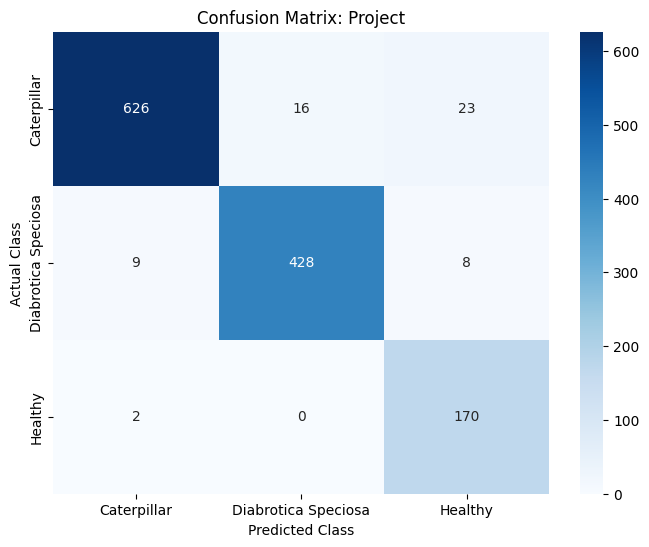

In [ ]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Set the model to evaluation mode for the Project
model.eval()

all_preds = []
all_labels = []

# 2. Iterate over the validation data to gather predictions
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Match the mixed precision used in the training loop for speed and consistency
        with torch.amp.autocast(device_type='cuda'):
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

        # Move tensors to the CPU and convert to numpy arrays
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 3. Define the explicit class names
target_names = ['Caterpillar', 'Diabrotica Speciosa', 'Healthy']

# 4. Generate the Classification Report
print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=target_names))

# 5. Generate the Confusion Matrix
conf_matrix = confusion_matrix(all_labels, all_preds)
print("\nConfusion Matrix:")
print(conf_matrix)

# 6. Plot the Confusion Matrix visually
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion Matrix: Project")
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()


In [ ]:
import torch
from google.colab import files

# 1. Define the filename for your saved model
model_filename = 'resnet50_ft.pth'

# 2. Save the model's state dictionary (weights)
torch.save(model.state_dict(), model_filename)
print(f"✅ Model weights successfully saved locally as '{model_filename}'")

# 3. Trigger the browser download to your local machine
print("⏳ Starting download to your computer... Please check your browser popups.")
files.download(model_filename)



✅ Model weights successfully saved locally as 'resnet50_ft.pth'
⏳ Starting download to your computer... Please check your browser popups.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>